# TP4 – Workflow Machine Learning complet, puis passage à l'échelle avec Spark

Workflow : **Data → EDA → Prétraitement → Transformation → ML → Évaluation → Déploiement**

| Étape du TP | Jeu de données (Kaggle) | Outils |
|---|---|---|
| **1) Exemple « non Big Data »** | [World Data Centers](https://www.kaggle.com/datasets/rockyt0/world-data-centers) (4 802 lignes) | pandas + scikit-learn |
| **2) Big Data = Hadoop/Spark + 1)** | [Full Body Checkup Lab](https://www.kaggle.com/datasets/opendataforresearch/full-body-checkup-lab-dataset) (~250 000 bilans × 109 colonnes, 12 CSV ≈ 430 Mo) | PySpark (DataFrame, SQL, MLlib), Parquet |
| 3) | World Data Centers refait avec Spark | PySpark MLlib (même workflow qu'en 1) |

Les CSV sont attendus dans `world_data/` et `checkup_data/` (non versionnés, cf. `.gitignore`).

In [1]:
import os, glob, warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
os.makedirs("models", exist_ok=True)

# Partie 1 – World Data Centers (pandas + scikit-learn)

**Problème** : à partir des caractéristiques d'un data center recensé dans OpenStreetMap (surface au sol, position, continent,
présence d'un opérateur, d'un site web…), prédire son **type** : `colocation`, `hyperscale` ou `telecom_carrier`.
(Les 3 226 sites `unclassified` n'ont pas de label : ils sont exclus de l'entraînement.)

## 1.1 Data

In [2]:
dc = pd.read_csv("world_data/data_centers.csv", low_memory=False)
print(dc.shape); dc[["name","operator","facility_kind","country","continent","latitude","longitude","footprint_area_m2"]].head()

(4802, 32)


,name,operator,facility_kind,country,continent,latitude,longitude,footprint_area_m2
0,ISPPro.al,NaN,unclassified,Albania,Europe,42.121369,19.561237,110.0
1,NaN,NaN,unclassified,Angola,Africa,-14.813566,13.441489,69.0
2,Centro de Datos Modular REFSA Telecomunicaciones,NaN,telecom_carrier,Argentina,South America,-26.205855,-58.207081,NaN
3,Centro de Datos UPSTI,NaN,unclassified,Argentina,South America,-26.182862,-58.164591,NaN
4,Claro,NaN,unclassified,Argentina,South America,-30.866751,-64.519637,26.0


## 1.2 EDA

facility_kind
unclassified            3226
colocation               723
hyperscale               604
telecom_carrier          160
research_or_academic      42
financial                 38
government_or_public       9
Name: count, dtype: int64 

% de valeurs manquantes (top 10) :
brand              99.4
wikipedia          98.9
name_en            98.3
wikidata           97.5
owner              97.1
height_m           96.5
start_date         96.0
operator_short     92.5
building_levels    91.5
state              81.5
dtype: float64


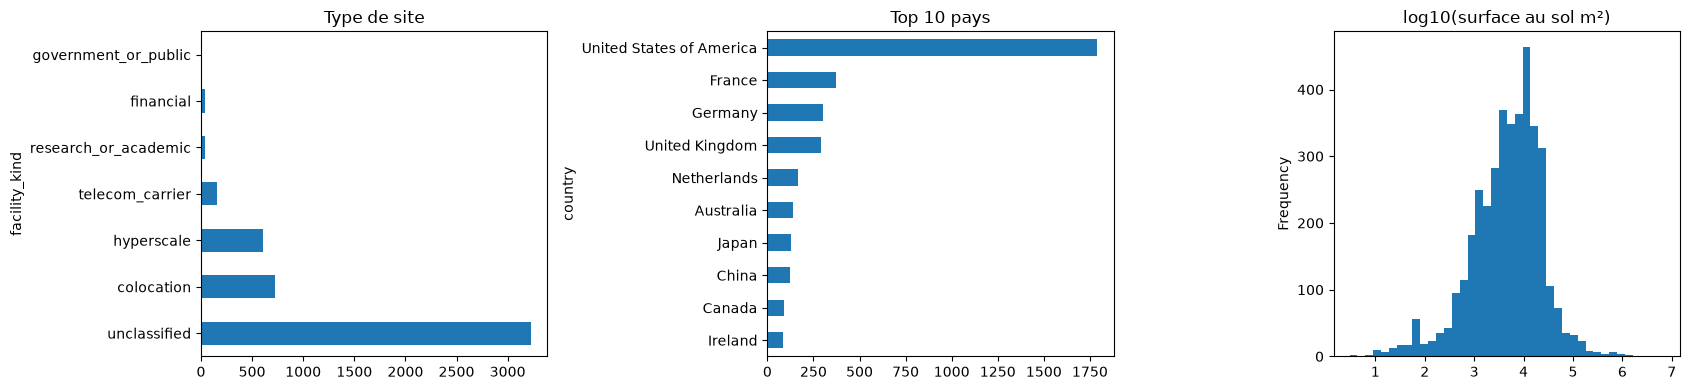

facility_kind
colocation               7406.0
financial                7090.0
government_or_public     1324.0
hyperscale              15675.0
research_or_academic     1452.0
telecom_carrier          2322.0
unclassified             3993.0
Name: footprint_area_m2, dtype: float64


In [3]:
print(dc.facility_kind.value_counts(), "\n")
print("% de valeurs manquantes (top 10) :"); print((dc.isna().mean()*100).round(1).sort_values(ascending=False).head(10))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
dc.facility_kind.value_counts().plot.barh(ax=ax[0], title="Type de site")
dc.country.value_counts().head(10).plot.barh(ax=ax[1], title="Top 10 pays").invert_yaxis()
np.log10(dc.footprint_area_m2.dropna()).plot.hist(bins=40, ax=ax[2], title="log10(surface au sol m²)")
plt.tight_layout(); plt.show()
print(dc.groupby("facility_kind").footprint_area_m2.median().round(0))

**Observations** : classes très déséquilibrées (67 % `unclassified`), surface manquante pour ~19 %, distribution de surface log-normale
(d'où le `log10`), les `hyperscale` sont nettement plus grands que les autres.

## 1.3 Prétraitement
Filtrage des 3 classes cibles, suppression des identifiants/texte libre (risque de fuite : le nom contient souvent « AWS », « Equinix »…),
création d'indicateurs de présence, log de la surface, séparation train/test stratifiée **avant** toute imputation (pas de fuite).

In [4]:
from sklearn.model_selection import train_test_split
targets = ["colocation", "hyperscale", "telecom_carrier"]
d = dc[dc.facility_kind.isin(targets)].copy()
d["log_area"]     = np.log10(d.footprint_area_m2)
d["has_operator"] = d.operator.notna().astype(int)
d["has_name"]     = d.name.notna().astype(int)
d["has_website"]  = d.website.notna().astype(int)
d["has_city"]     = d.city.notna().astype(int)
d["is_way"]       = (d.osm_type == "way").astype(int)
num = ["log_area", "latitude", "longitude", "has_operator", "has_name", "has_website", "has_city", "is_way"]
cat = ["continent"]
X, y = d[num + cat], d.facility_kind
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(Xtr.shape, Xte.shape); ytr.value_counts(normalize=True).round(3)

(1115, 9) (372, 9)


facility_kind
colocation         0.486
hyperscale         0.406
telecom_carrier    0.108
Name: proportion, dtype: float64

## 1.4 Transformation
Imputation (médiane) + standardisation des numériques, one-hot du continent, le tout dans un `Pipeline` scikit-learn.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

## 1.5 Machine Learning
Deux modèles comparés par validation croisée (F1 macro, adapté au déséquilibre) : régression logistique et forêt aléatoire, avec `class_weight='balanced'`.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
models = {"LogReg": LogisticRegression(max_iter=2000, class_weight="balanced"),
          "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
pipes = {k: Pipeline([("prep", prep), ("m", m)]) for k, m in models.items()}
for k, p in pipes.items():
    s = cross_val_score(p, Xtr, ytr, cv=cv, scoring="f1_macro")
    print(f"{k:13s} F1-macro CV = {s.mean():.3f} ± {s.std():.3f}")

LogReg        F1-macro CV = 0.640 ± 0.020


RandomForest  F1-macro CV = 0.755 ± 0.038


## 1.6 Évaluation (jeu de test)

                 precision    recall  f1-score   support

     colocation       0.85      0.82      0.84       181
     hyperscale       0.87      0.88      0.88       151
telecom_carrier       0.43      0.47      0.45        40

       accuracy                           0.81       372
      macro avg       0.72      0.73      0.72       372
   weighted avg       0.81      0.81      0.81       372



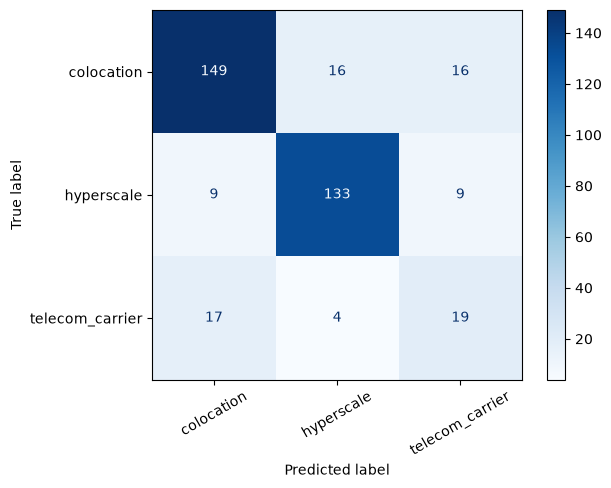

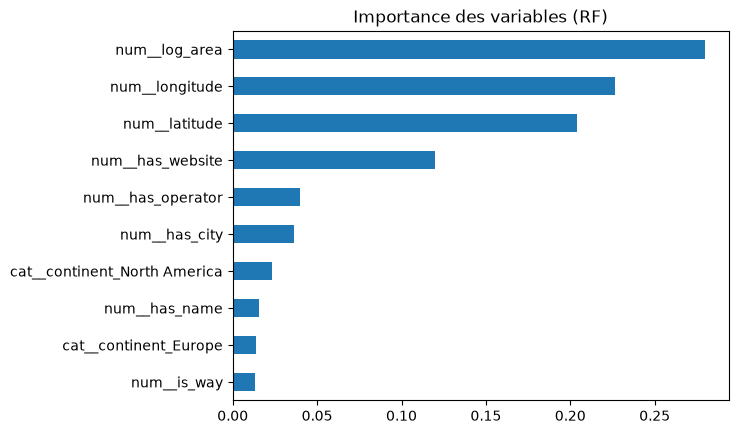

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
best_sk = pipes["RandomForest"].fit(Xtr, ytr)
pred = best_sk.predict(Xte)
print(classification_report(yte, pred))
ConfusionMatrixDisplay.from_predictions(yte, pred, xticks_rotation=30, cmap="Blues"); plt.show()
names = best_sk.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_sk.named_steps["m"].feature_importances_, index=names).sort_values()
imp.tail(10).plot.barh(title="Importance des variables (RF)"); plt.show()

## 1.7 Déploiement
Sauvegarde du pipeline complet (prétraitement + modèle) avec `joblib` et fonction de prédiction réutilisable (cf. `predict_datacenter.py`).

In [8]:
import joblib
joblib.dump(best_sk, "models/datacenter_rf.joblib")
loaded = joblib.load("models/datacenter_rf.joblib")
new_site = pd.DataFrame([dict(log_area=np.log10(60000), latitude=45.5, longitude=-122.6, has_operator=1, has_name=1,
                              has_website=1, has_city=1, is_way=1, continent="North America")])
print("Prédiction :", loaded.predict(new_site)[0]); print(dict(zip(loaded.classes_, loaded.predict_proba(new_site)[0].round(3))))

Prédiction : colocation
{'colocation': np.float64(0.973), 'hyperscale': np.float64(0.02), 'telecom_carrier': np.float64(0.007)}


# Partie 2 – Big Data : Full Body Checkup Lab avec Spark

**Pourquoi Spark ?** 12 fichiers mensuels (Août 2018 → Juillet 2019) × ~20 800 bilans × 109 analyses, soit ~430 Mo de CSV :
on lit tous les fichiers en parallèle (partitions), on stocke en **Parquet** (format colonnaire, standard de l'écosystème Hadoop/HDFS) et on
entraîne avec **MLlib**. En cluster il suffirait de remplacer `local[*]` par YARN et `checkup_data/` par un chemin `hdfs://…`.

**Problème** : prédire le **pré-diabète/diabète** (`hba1c ≥ 5,7 %`) à partir des *autres* analyses et du profil du patient.
Les variables directement liées à la glycémie (`fasting_glucose, fbs, plbs, pp_glucose, eag`) sont **exclues** : sinon on ne ferait que retrouver la cible (fuite de données).

## 2.1 Data

In [9]:
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.master("local[*]").appName("TP4-Checkup")
         .config("spark.driver.memory", "6g").config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.legacy.timeParserPolicy", "LEGACY").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
files = sorted(f for f in glob.glob("checkup_data/*.csv") if "SubjectDetails" not in f)
print(len(files), "fichiers mensuels :", [os.path.basename(f) for f in files])
labs = spark.read.csv(files, header=True, inferSchema=True)
subj = spark.read.csv("checkup_data/SubjectDetails.csv", header=True, inferSchema=True)
print("bilans :", labs.count(), "x", len(labs.columns), "| patients :", subj.count(), "| partitions :", labs.rdd.getNumPartitions())

12 fichiers mensuels : ['Apr19.csv', 'Aug18.csv', 'Dec18.csv', 'Feb19.csv', 'Jan19.csv', 'Jul19.csv', 'Jun19.csv', 'Mar19.csv', 'May19.csv', 'Nov18.csv', 'Oct18.csv', 'Sep18.csv']


bilans : 250164 x 109 | patients : 20847 | partitions : 12


## 2.2 EDA (Spark SQL / DataFrame)

In [10]:
labs = labs.withColumn("month", F.date_format(F.to_date("Collected Dt", "d MMMM yyyy"), "yyyy-MM"))
labs.createOrReplaceTempView("labs"); subj.createOrReplaceTempView("subj")
spark.sql("SELECT month, COUNT(*) n, ROUND(AVG(hba1c),3) hba1c_moy, ROUND(AVG(fasting_glucose),1) gly_moy, ROUND(AVG(systolic_bp),1) tas_moy FROM labs GROUP BY month ORDER BY month").show()
spark.sql("SELECT Zender, COUNT(*) n FROM subj GROUP BY Zender ORDER BY n DESC").show()
spark.sql("SELECT Diet, COUNT(*) n FROM subj GROUP BY Diet ORDER BY n DESC").show()

+-------+-----+---------+-------+-------+
|  month|    n|hba1c_moy|gly_moy|tas_moy|
+-------+-----+---------+-------+-------+
|   NULL|41694|    5.403|   92.0|  118.2|
|2018-08|20847|    5.404|   92.0|  118.2|
|2018-09|20847|    5.397|   91.9|  118.0|
|2018-11|20847|    5.396|   91.9|  118.2|
|2018-12|20847|      5.4|   91.9|  118.0|
|2019-01|20847|    5.399|   92.0|  118.3|
|2019-03|20847|    5.398|   91.8|  118.2|
|2019-04|20847|      5.4|   92.0|  118.1|
|2019-05|20847|    5.396|   91.9|  118.0|
|2019-06|20847|    5.408|   92.2|  118.1|
|2019-07|20847|    5.401|   92.0|  118.0|
+-------+-----+---------+-------+-------+



+------+-----+
|Zender|    n|
+------+-----+
|  Male|10215|
|Female| 9113|
|  TrFe|  754|
|  PNTD|  511|
|    NS|  250|
|TrMale|    4|
+------+-----+



+------+----+
|  Diet|   n|
+------+----+
|   Veg|8381|
|NonVeg|7287|
|    NS|2618|
|  PNTD|1516|
| Vegan|1045|
+------+----+



Colonnes avec valeurs manquantes :
month    41694
Name: 0, dtype: int64


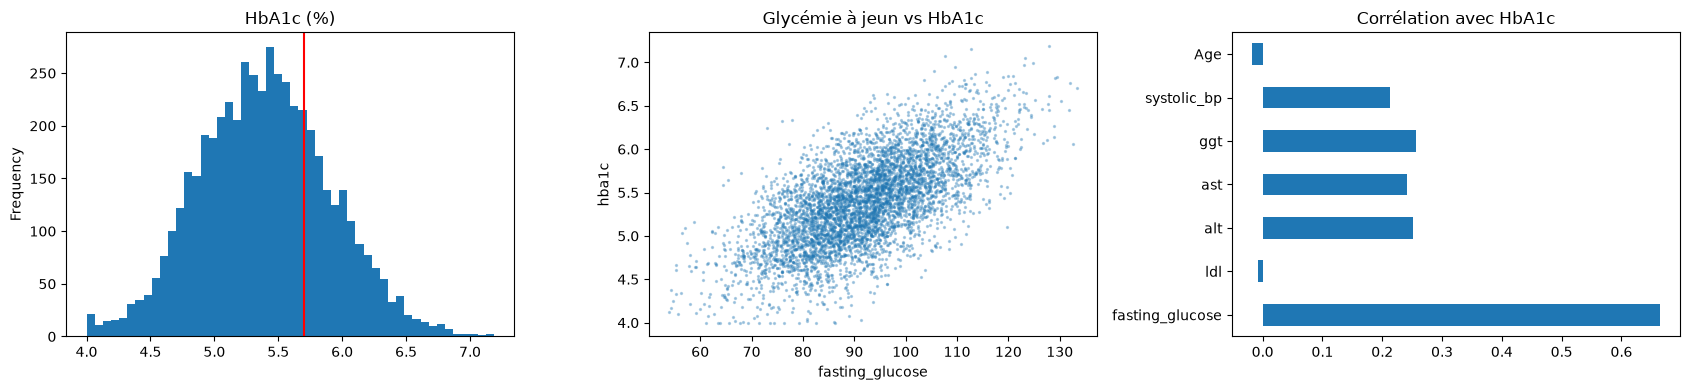

In [11]:
nulls = labs.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in labs.columns]).toPandas().T[0]
print("Colonnes avec valeurs manquantes :"); print(nulls[nulls > 0].sort_values(ascending=False).head(10))
# échantillon (2 %) ramené côté pandas pour les graphiques
smp = labs.join(subj.select("MedID","Age"), "MedID").sample(0.02, seed=1).select("hba1c","fasting_glucose","ldl","alt","ast","ggt","systolic_bp","Age").toPandas()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
smp.hba1c.plot.hist(bins=50, ax=ax[0], title="HbA1c (%)"); ax[0].axvline(5.7, c="r")
smp.plot.scatter("fasting_glucose", "hba1c", s=2, alpha=.3, ax=ax[1], title="Glycémie à jeun vs HbA1c")
smp.corr()["hba1c"].drop("hba1c").plot.barh(ax=ax[2], title="Corrélation avec HbA1c"); plt.tight_layout(); plt.show()

## 2.3 Prétraitement
Jointure bilan ↔ patient (`MedID`), harmonisation de la colonne `Zender` (6 variantes), création de la cible, suppression des variables fuyantes et
des identifiants. Le jeu nettoyé est écrit en **Parquet** ; l'imputation des manquants (médiane) se fait dans le pipeline (section 2.4).

In [12]:
subj.groupBy("Zender").count().show()
sub = (subj.select("MedID", "Age", F.col("Reg Weight").alias("weight"), "Diet", "Smoking", "Drinking",
        F.when(F.lower(F.col("Zender")).startswith("m"), "Male").when(F.lower(F.col("Zender")).startswith("f"), "Female").otherwise("Other").alias("sex")))
df = labs.join(sub, "MedID").withColumn("label", (F.col("hba1c") >= 5.7).cast("double")).where(F.col("hba1c").isNotNull())
leak = ["hba1c", "eag", "fasting_glucose", "fbs", "plbs", "pp_glucose"]
ids = ["MedID", "Sample ID", "Collected From", "Collected Dt", "Collected Tm", "Reported Time", "month"]
num_cols = [c for c, t in df.dtypes if t in ("int", "bigint", "double") and c not in leak + ids + ["label"]]
cat_cols = ["sex", "Diet", "Smoking", "Drinking"]
df = df.select("MedID", "label", *num_cols, *cat_cols)
print(len(num_cols), "variables numériques,", len(cat_cols), "catégorielles")
df.groupBy("label").count().show()
df.write.mode("overwrite").parquet("checkup_clean.parquet")
df = spark.read.parquet("checkup_clean.parquet").cache(); print("lignes :", df.count())

+------+-----+
|Zender|count|
+------+-----+
|TrMale|    4|
|    NS|  250|
|  Male|10215|
|  TrFe|  754|
|  PNTD|  511|
|Female| 9113|
+------+-----+



85 variables numériques, 4 catégorielles


+-----+------+
|label| count|
+-----+------+
|  1.0| 68552|
|  0.0|181612|
+-----+------+



lignes : 250164


**Séparation train/test par patient** : un même patient apparaît dans les 12 mois ; un split aléatoire par ligne mettrait le même patient
des deux côtés et gonflerait les scores. On découpe donc sur un hash de `MedID`.

In [13]:
bucket = F.abs(F.hash("MedID")) % 100
train, test = df.where(bucket < 80), df.where(bucket >= 80)
print("train :", train.count(), "| test :", test.count())

train : 200148 | test : 50016


## 2.4 Transformation (MLlib)
`Imputer` (médiane) → `StringIndexer` + `OneHotEncoder` → `VectorAssembler` → `StandardScaler`.

In [14]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
imputed = [c + "_imp" for c in num_cols]
stages = [Imputer(inputCols=num_cols, outputCols=imputed, strategy="median"),
          StringIndexer(inputCols=cat_cols, outputCols=[c + "_idx" for c in cat_cols], handleInvalid="keep"),
          OneHotEncoder(inputCols=[c + "_idx" for c in cat_cols], outputCols=[c + "_oh" for c in cat_cols]),
          VectorAssembler(inputCols=imputed + [c + "_oh" for c in cat_cols], outputCol="raw"),
          StandardScaler(inputCol="raw", outputCol="features", withMean=False)]

## 2.5 Machine Learning
Régression logistique, forêt aléatoire et GBT (MLlib), entraînés en parallèle sur les partitions.

In [15]:
import time
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
algos = {"LogReg": LogisticRegression(labelCol="label", featuresCol="features", maxIter=50),
         "RandomForest": RandomForestClassifier(labelCol="label", featuresCol="features", numTrees=60, maxDepth=7, seed=42),
         "GBT": GBTClassifier(labelCol="label", featuresCol="features", maxIter=30, maxDepth=5, seed=42)}
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
fitted, res = {}, []
for name, algo in algos.items():
    t = time.time(); m = Pipeline(stages=stages + [algo]).fit(train); fitted[name] = m
    res.append((name, round(auc.evaluate(m.transform(test)), 4), round(time.time() - t, 1)))
pd.DataFrame(res, columns=["modèle", "AUC test", "temps (s)"])

,modèle,AUC test,temps (s)
0,LogReg,0.6871,57.5
1,RandomForest,0.6552,53.7
2,GBT,0.6852,68.6


## 2.6 Évaluation

In [16]:
best_name = max(res, key=lambda r: r[1])[0]; best = fitted[best_name]; pred = best.transform(test)
print("Meilleur modèle :", best_name)
for m in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
    print(f"{m:18s}", round(MulticlassClassificationEvaluator(labelCol="label", metricName=m).evaluate(pred), 4))
cm = pred.groupBy("label", "prediction").count().toPandas().pivot(index="label", columns="prediction", values="count")
print("Matrice de confusion (lignes = réel, colonnes = prédit) :"); print(cm)
print("Prévalence de la classe positive (test) :", round(test.agg(F.avg("label")).first()[0], 3))
# importance des variables numériques (modèles à base d'arbres)
if best_name != "LogReg":
    fi = best.stages[-1].featureImportances.toArray()
    pd.Series(fi[:len(num_cols)], index=num_cols).sort_values().tail(12).plot.barh(title=f"Importance des variables ({best_name})"); plt.show()

Meilleur modèle : LogReg


accuracy           0.737


f1                 0.6764


weightedPrecision  0.7017


weightedRecall     0.737


Matrice de confusion (lignes = réel, colonnes = prédit) :
prediction    0.0   1.0
label                  
0.0         34792  1535
1.0         11618  2071


Prévalence de la classe positive (test) : 0.274


**Lecture** : l'AUC et le F1 se lisent par rapport à la prévalence de la classe positive (un classifieur constant aurait AUC = 0,5 et une accuracy égale à la
fréquence de la classe majoritaire).

**Résultat** : AUC ≈ 0,69 (régression logistique et GBT), la forêt aléatoire fait moins bien (0,66). Le signal est modeste : sans les mesures de glycémie, les autres analyses expliquent mal l'HbA1c (prévalence positive ≈ 27 %, accuracy 0,74 pour un classifieur constant à 0,73). Le gain du Big Data ici est de pouvoir le démontrer rapidement sur 250 000 lignes, pas d'obtenir un modèle clinique.

## 2.7 Déploiement
Sauvegarde du `PipelineModel` complet (format Spark, stockable sur HDFS), rechargement, et scoring d'un nouveau lot de patients (batch) – cf. `score_checkup.py`.

In [17]:
best.write().overwrite().save("models/checkup_spark_model")
from pyspark.ml import PipelineModel
loaded_model = PipelineModel.load("models/checkup_spark_model")
from pyspark.ml.functions import vector_to_array
loaded_model.transform(test.limit(5)).select("MedID", "label", F.round(vector_to_array("probability")[1], 3).alias("proba_prediabete"), "prediction").show()

+------+-----+----------------+----------+
| MedID|label|proba_prediabete|prediction|
+------+-----+----------------+----------+
|100148|  1.0|           0.338|       0.0|
|100499|  1.0|           0.178|       0.0|
|100603|  0.0|           0.235|       0.0|
|100700|  1.0|           0.127|       0.0|
|100767|  0.0|           0.407|       0.0|
+------+-----+----------------+----------+



# Partie 3 – 1) + Spark : World Data Centers avec MLlib

On rejoue le même workflow qu'en Partie 1 avec Spark (l'intérêt est la **portabilité** du code vers des volumes supérieurs) et on ajoute une
agrégation SQL par pays, jointe à `reported_totals.csv` (comptages officiels publiés), pour mesurer la couverture d'OpenStreetMap.

In [18]:
dcs = spark.read.csv("world_data/data_centers.csv", header=True, inferSchema=True, multiLine=True, escape='"')
dcs.createOrReplaceTempView("dc")
spark.read.csv("world_data/reported_totals.csv", header=True, inferSchema=True).createOrReplaceTempView("rep")
spark.sql('''SELECT d.country, COUNT(*) osm, MAX(r.reported_facilities) reported,
             ROUND(100*COUNT(*)/MAX(r.reported_facilities),1) pct_couverture_osm,
             SUM(CASE WHEN facility_kind='hyperscale' THEN 1 ELSE 0 END) hyperscale
             FROM dc d JOIN rep r ON d.country_iso3 = r.country_iso3
             GROUP BY d.country ORDER BY osm DESC LIMIT 10''').show(truncate=False)

+------------------------+----+--------+------------------+----------+
|country                 |osm |reported|pct_couverture_osm|hyperscale|
+------------------------+----+--------+------------------+----------+
|United States of America|3578|4088    |87.5              |886       |
|France                  |742 |346     |214.5             |2         |
|Germany                 |600 |507     |118.3             |0         |
|United Kingdom          |586 |506     |115.8             |18        |
|Netherlands             |334 |187     |178.6             |30        |
|Australia               |278 |270     |103.0             |30        |
|Japan                   |254 |255     |99.6              |2         |
|China                   |250 |369     |67.8              |4         |
|Canada                  |176 |286     |61.5              |6         |
|Ireland                 |172 |128     |134.4             |78        |
+------------------------+----+--------+------------------+----------+



In [19]:
sd = (dcs.where(F.col("facility_kind").isin(targets))
      .withColumn("log_area", F.log10(F.col("footprint_area_m2").cast("double")))
      .withColumn("latitude", F.col("latitude").cast("double")).withColumn("longitude", F.col("longitude").cast("double"))
      .withColumn("has_operator", F.col("operator").isNotNull().cast("int"))
      .withColumn("has_name", F.col("name").isNotNull().cast("int"))
      .withColumn("has_website", F.col("website").isNotNull().cast("int"))
      .withColumn("has_city", F.col("city").isNotNull().cast("int"))
      .withColumn("is_way", (F.col("osm_type") == "way").cast("int")))
flags = ["has_operator", "has_name", "has_website", "has_city", "is_way"]
tr, te = sd.randomSplit([.75, .25], seed=42)
pipe = Pipeline(stages=[
    Imputer(inputCols=["log_area"], outputCols=["log_area_imp"], strategy="median"),
    StringIndexer(inputCol="facility_kind", outputCol="lab"), StringIndexer(inputCol="continent", outputCol="cont_idx", handleInvalid="keep"),
    OneHotEncoder(inputCols=["cont_idx"], outputCols=["cont_oh"]),
    VectorAssembler(inputCols=["log_area_imp", "latitude", "longitude"] + flags + ["cont_oh"], outputCol="features"),
    RandomForestClassifier(labelCol="lab", featuresCol="features", numTrees=200, maxDepth=8, seed=42)])
pm = pipe.fit(tr); p = pm.transform(te)
for m in ["accuracy", "f1"]: print(m, round(MulticlassClassificationEvaluator(labelCol="lab", metricName=m).evaluate(p), 4))
print("classes :", pm.stages[1].labels)

accuracy 0.7969


f1 0.7816
classes : ['colocation', 'hyperscale', 'telecom_carrier']


# Conclusion

| | Partie 1 (pandas/sklearn) | Partie 2 (Spark) |
|---|---|---|
| Données | 4 802 sites, 1 CSV | ~250 000 bilans × 109 colonnes, 12 CSV |
| Lecture | `pd.read_csv` (mémoire d'un seul processus) | `spark.read.csv` parallélisé par partitions, stockage Parquet |
| Pipeline | `Pipeline` + `ColumnTransformer` | `Pipeline` MLlib (Imputer → Indexer → Assembler → Scaler) |
| Déploiement | `joblib` + `predict_datacenter.py` | `PipelineModel.save` + `score_checkup.py` (scoring batch) |

Points d'attention : **fuite de données** (variables glycémiques, noms de sites), **déséquilibre de classes**, et **split par patient** plutôt que par ligne.
Limite : les données du bilan semblent (semi-)synthétiques ; les scores ne préjugent donc pas d'une valeur clinique réelle.